In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import time
import sys
import importlib
from pathlib import Path

for project_root in (Path.cwd(), Path.cwd().parent):
    if (project_root / 'binary_sync').is_dir():
        sys.path.insert(0, str(project_root))
        break

# Clear previously imported project modules so notebook cells use current source.
for module_name in list(sys.modules):
    if module_name == 'binary_sync' or module_name.startswith('binary_sync.'):
        del sys.modules[module_name]
importlib.invalidate_caches()

from matplotlib.lines import Line2D
from binary_sync.model import sample_instance, Graph
from binary_sync.bp import bp_corr2
from binary_sync.spectral import spectral_corr2
from binary_sync.low_degree import low_degree_corr2 as low_degree_corr
from binary_sync.low_degree import low_degree_weights as compute_low_degree_weights, print_low_degree_weights
from binary_sync.percolation import estimate_percolation_bound
from binary_sync.reporting import format_estimate
from binary_sync.exact_corr_sp import sp_corr2
from binary_sync.acyclic_BP import acyclic_bp_corr2

In [36]:
def test_small_graph(p: float = 0.2) -> Graph:
    """
    Construct the 6-vertex, 9-edge graph

        E = {
            (1,2), (1,3), (1,4), (1,5),
            (2,3), (2,4), (2,6),
            (3,5), (3,6)
        }.

    Every edge has crossover probability p.
    """
    G = Graph()

    edges = [
        (1, 2),
        (1, 3),
        (1, 5),
        (2, 4),
        (2, 6),
        (2, 5),
        (3, 4)
    ]

    for u, v in edges:
        G.add_edge(u, v, p)

    return G


In [37]:
def draw_graph(graph, source, target, ax=None, seed=0, title=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))
    nx_graph = nx.MultiGraph()
    nx_graph.add_nodes_from(graph.nodes)
    for edge_id, edge in enumerate(graph.edges):
        nx_graph.add_edge(edge.u, edge.v, key=edge_id)
    positions = nx.spring_layout(nx_graph, seed=seed)
    nx.draw_networkx_edges(nx_graph, positions, ax=ax, width=1.8, edge_color="gray")
    ordinary_nodes = [node for node in graph.nodes if node not in {source, target}]
    nx.draw_networkx_nodes(nx_graph, positions, nodelist=ordinary_nodes, ax=ax, node_size=70, node_color="lightblue", edgecolors="black")
    nx.draw_networkx_nodes(nx_graph, positions, nodelist=[source], ax=ax, node_size=85, node_color="mediumseagreen", edgecolors="black", linewidths=2)
    nx.draw_networkx_nodes(nx_graph, positions, nodelist=[target], ax=ax, node_size=85, node_color="darkorange", edgecolors="black", linewidths=2)
    labels = {node: str(node) for node in graph.nodes}
    nx.draw_networkx_labels(nx_graph, positions, labels=labels, ax=ax, font_size=10)
    if title is not None:
        ax.set_title(title)
    ax.set_axis_off()
    return ax

<Axes: >

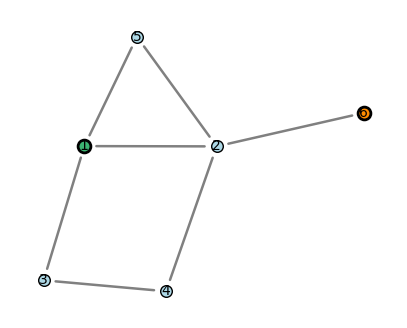

In [38]:
example = test_small_graph(0.2)
s, t = 1, 6
draw_graph(example, s, t)

In [42]:
result_low_degree = low_degree_corr(example, 7, s, t)
result_spectral = spectral_corr2(example, s, t, alg="naive", n_samples=10000, seed=3)
print(f"Low-degree: {format_estimate(result_low_degree)}")
print(f"Spectral: {format_estimate(result_spectral['corr2'])}")

Low-degree: estimate=0.156570, standard error=0.000000, 95% CI=[0.156570, 0.156570]
Spectral: estimate=0.109693, standard error=0.000000, 95% CI=[0.109693, 0.109693]


In [43]:
result_acyclic_sp = acyclic_bp_corr2(example, s, t, n_samples=50000)
print(f"Acyclic BP: {format_estimate(result_acyclic_sp['corr2'], result_acyclic_sp['standard error'])}")

Acyclic BP: estimate=0.150080, standard error=0.003089, 95% CI=[0.144025, 0.156136]
